<img src = "https://drive.google.com/uc?export=view&id=10DJdk95gzrY6H-dKEFKshN814gdMc9FV" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento y Preparación de los Datos**
---

Este notebook corresponde al **segundo entregable del proyecto aplicado**: el análisis de entendimiento de los datos del conjunto *Heart Failure Prediction Dataset*. Se documentan la estructura general del conjunto, la verificación de su calidad, los tipos de variables con su análisis descriptivo y las relaciones entre variables. En esta fase **no se aplican transformaciones**: la exploración se realiza sobre los datos originales, tal como fueron cargados.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. **Hernando Jose Vela — 17593509**
2. **Oscar Javier Restrepo — 79660922**
3. **Juan David Vasquez Pinzon — 1002459526**

## **Carga de los Datos**
---

Esta fase continúa el proyecto aplicado iniciado en la fase 1 (*Entendimiento del Negocio y Carga de Datos*). Se utilizará el mismo conjunto de datos: **Heart Failure Prediction Dataset**, publicado por el usuario **fedesoriano** en Kaggle.

- **Fuente:** [Heart Failure Prediction Dataset en Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction).
- **Archivo:** `heart.csv` (918 registros y 12 columnas según la documentación de la fuente).

**Procedimiento de carga**

1. Se descarga automáticamente el archivo comprimido desde la API pública de Kaggle mediante la biblioteca `requests`.
2. Se extrae el archivo `heart.csv` del ZIP en memoria con la biblioteca `zipfile`.
3. Se lee el contenido con la función `read_csv()` de `pandas`.
4. Se verifica que el archivo contenga las columnas esperadas.
5. Se conservan una copia de referencia (`df_original`) y una copia de trabajo (`df`).

En esta fase **no se aplicarán transformaciones** a los datos: la exploración se realizará sobre los datos originales, tal como fueron cargados.

In [ ]:
# @title
# Bibliotecas estándar de Python.
import io
import os
import hashlib
import zipfile
from datetime import datetime, timezone

# Bibliotecas de análisis y visualización.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Mostrar tablas con formato enriquecido en el notebook.
from IPython.display import display


# Las constantes centralizan la configuración del conjunto de datos.
DATASET_NAME = "Heart Failure Prediction Dataset"
DATASET_AUTHOR = "fedesoriano"
SOURCE_URL = (
    "https://www.kaggle.com/datasets/"
    "fedesoriano/heart-failure-prediction"
)
DOWNLOAD_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "fedesoriano/heart-failure-prediction"
)
DATASET_FILE = "heart.csv"

# Se utilizarán estos nombres para comprobar la estructura del archivo.
EXPECTED_COLUMNS = [
    "Age",
    "Sex",
    "ChestPainType",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "RestingECG",
    "MaxHR",
    "ExerciseAngina",
    "Oldpeak",
    "ST_Slope",
    "HeartDisease",
]

# Clasificación conceptual de las variables (definida en la fase 1).
numeric_columns = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
categorical_columns = [
    "Sex",
    "ChestPainType",
    "FastingBS",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope",
]
target_column = "HeartDisease"

# Etiquetas en español para facilitar la lectura de tablas y gráficas.
numeric_labels = {
    "Age": "Edad (años)",
    "RestingBP": "Presión arterial en reposo (mmHg)",
    "Cholesterol": "Colesterol (mg/dL)",
    "MaxHR": "Frecuencia cardíaca máxima (lpm)",
    "Oldpeak": "Depresión del segmento ST",
}

categorical_labels = {
    "Sex": "Sexo",
    "ChestPainType": "Tipo de dolor torácico",
    "FastingBS": "Glucemia en ayunas > 120 mg/dL",
    "RestingECG": "Electrocardiograma en reposo",
    "ExerciseAngina": "Angina inducida por ejercicio",
    "ST_Slope": "Pendiente del segmento ST",
}

target_labels = {0: "Sin enfermedad cardíaca", 1: "Con enfermedad cardíaca"}

# Estilo visual consistente para todas las gráficas.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Bibliotecas y configuración listas.")

Bibliotecas y configuración listas.


In [ ]:
# @title
# Descargar automáticamente el archivo desde la API pública de Kaggle.
# El procedimiento no requiere interacción humana ni credenciales.
print(f"Descargando {DATASET_NAME} desde la fuente...")

response = requests.get(DOWNLOAD_URL, timeout=60)
response.raise_for_status()
print("Descarga completada con éxito.")

# Extraer heart.csv del ZIP descargado, procesándolo en memoria.
try:
    with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
        available_files = zip_ref.namelist()

        if DATASET_FILE not in available_files:
            raise ValueError(
                f"El ZIP no contiene el archivo esperado '{DATASET_FILE}'. "
                f"Archivos disponibles: {available_files}"
            )

        file_content = zip_ref.read(DATASET_FILE)
except zipfile.BadZipFile as error:
    raise ValueError(
        "El archivo descargado no es un ZIP válido. "
        "Verifique la conexión y la URL de descarga."
    ) from error

print("Archivo heart.csv extraído con éxito.")

# Guardar el archivo en disco para poder documentar su tamaño real.
with open(DATASET_FILE, "wb") as f:
    f.write(file_content)

# Leer el CSV con pandas, manteniendo compatibilidad con UTF-8 con BOM.
try:
    loaded_data = pd.read_csv(
        DATASET_FILE,
        encoding="utf-8-sig",
        sep=",",
    )
except pd.errors.EmptyDataError as error:
    raise ValueError("El archivo descargado está vacío.") from error
except pd.errors.ParserError as error:
    raise ValueError(
        "No se pudo interpretar el CSV. Verifique la estructura del archivo."
    ) from error

# Confirmar que el archivo contiene registros.
if loaded_data.empty:
    raise ValueError("El archivo contiene encabezados, pero no tiene registros.")

print(f"\nArchivo leído: {DATASET_FILE}")
print(f"Filas: {loaded_data.shape[0]}")
print(f"Columnas: {loaded_data.shape[1]}")

Descargando Heart Failure Prediction Dataset desde la fuente...
Descarga completada con éxito.
Archivo heart.csv extraído con éxito.

Archivo leído: heart.csv
Filas: 918
Columnas: 12


In [ ]:
# @title
# Comparar las columnas presentes con las descritas para el conjunto.
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(loaded_data.columns))
additional_columns = sorted(set(loaded_data.columns) - set(EXPECTED_COLUMNS))

# Las columnas faltantes pueden indicar que se descargó otro conjunto
# de datos o que el archivo fue modificado.
if missing_columns:
    raise ValueError(
        f"Faltan las siguientes columnas: {missing_columns}. "
        "Verifica que utilizas heart.csv del usuario fedesoriano."
    )

# Informar sobre columnas adicionales sin eliminarlas automáticamente.
if additional_columns:
    print("Columnas adicionales que requieren revisión:", additional_columns)

# Conservar una copia de referencia y otra para el trabajo posterior.
df_original = loaded_data.copy(deep=True)
df = df_original.copy(deep=True)

# Las dimensiones publicadas sirven como referencia, no como limpieza.
expected_shape = (918, 12)

if df.shape == expected_shape:
    print("Las dimensiones coinciden con la descripción: 918 filas y 12 columnas.")
else:
    print(
        f"Las dimensiones observadas son {df.shape}; "
        f"la referencia publicada es {expected_shape}. "
        "Se debe documentar y revisar esta diferencia."
    )

# Calcular una huella digital del contenido original del archivo.
file_sha256 = hashlib.sha256(file_content).hexdigest()

# Registrar la procedencia de los datos para esta fase.
acquisition_log = {
    "Conjunto": DATASET_NAME,
    "Publicador en Kaggle": DATASET_AUTHOR,
    "Fuente": SOURCE_URL,
    "Archivo cargado": DATASET_FILE,
    "Método": "Descarga automática desde la API de Kaggle (entorno local)",
    "Fecha de carga (UTC)": datetime.now(timezone.utc).isoformat(
        timespec="seconds"
    ),
    "Número de filas": df_original.shape[0],
    "Número de columnas": df_original.shape[1],
    "SHA-256": file_sha256,
}

print("\nRegistro de adquisición:")
display(pd.DataFrame(acquisition_log.items(), columns=["Campo", "Valor"]))

# Mostrar una muestra para comprobar visualmente la lectura.
print("\nMuestra de los datos cargados:")
display(df.head())

Las dimensiones coinciden con la descripción: 918 filas y 12 columnas.

Registro de adquisición:


,Campo,Valor
0,Conjunto,Heart Failure Prediction Dataset
1,Publicador en Kaggle,fedesoriano
2,Fuente,https://www.kaggle.com/datasets/fedesoriano/he...
3,Archivo cargado,heart.csv
4,Método,Descarga automática desde la API de Kaggle (en...
5,Fecha de carga (UTC),2026-10-19T18:15:37+00:00
6,Número de filas,918
7,Número de columnas,12
8,SHA-256,948420b084d8a3a0ca42b8419fce9aee175879e43f8aed...



Muestra de los datos cargados:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## **1. Análisis Exploratorio de los Datos**
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

**Resumen general del conjunto de datos**

La siguiente celda calcula los aspectos generales del conjunto: número de registros, formato de almacenamiento, tamaño del archivo y dimensiones de la tabla.

In [ ]:
# @title
# Calcular el tamaño del archivo en disco y en memoria.
file_size_bytes = os.path.getsize(DATASET_FILE)
file_size_mb = file_size_bytes / (1024**2)
memory_size_mb = df.memory_usage(deep=True).sum() / (1024**2)

# Consolidar el resumen general del conjunto de datos.
general_summary = pd.DataFrame([
    {
        "Aspecto": "Número de documentos (registros)",
        "Resultado": f"{df.shape[0]} registros",
    },
    {
        "Aspecto": "Número de variables (columnas)",
        "Resultado": f"{df.shape[1]} columnas",
    },
    {
        "Aspecto": "Variables predictoras",
        "Resultado": f"{len(numeric_columns)} numéricas y "
        f"{len(categorical_columns)} categóricas",
    },
    {
        "Aspecto": "Variable objetivo",
        "Resultado": f"{target_column} (binaria: 0 = sin enfermedad, "
        "1 = con enfermedad)",
    },
    {
        "Aspecto": "Formato de almacenamiento",
        "Resultado": "CSV (valores separados por comas, codificación UTF-8)",
    },
    {
        "Aspecto": "Tamaño del archivo en disco",
        "Resultado": f"{file_size_bytes:,} bytes "
        f"({file_size_mb:.4f} MB)",
    },
    {
        "Aspecto": "Tamaño en memoria (DataFrame)",
        "Resultado": f"{memory_size_mb:.4f} MB",
    },
    {
        "Aspecto": "Tipo de datos",
        "Resultado": "Datos estructurados y tabulares "
        "(una fila por paciente, una columna por variable)",
    },
])

display(general_summary)

,Aspecto,Resultado
0,Número de documentos (registros),918 registros
1,Número de variables (columnas),12 columnas
2,Variables predictoras,5 numéricas y 6 categóricas
3,Variable objetivo,"HeartDisease (binaria: 0 = sin enfermedad, 1 =..."
4,Formato de almacenamiento,"CSV (valores separados por comas, codificación..."
5,Tamaño del archivo en disco,"35,921 bytes (0.0343 MB)"
6,Tamaño en memoria (DataFrame),0.3098 MB
7,Tipo de datos,Datos estructurados y tabulares (una fila por ...


**Respuesta**

- **¿Cuántos documentos tiene el *dataset*?** El conjunto contiene **918 documentos (registros)**, donde cada registro representa un paciente, descritos por **12 variables** (11 predictoras y 1 variable objetivo). Las dimensiones observadas coinciden exactamente con las publicadas en la documentación de la fuente (918 filas × 12 columnas).

- **¿En qué formato están almacenados los datos?** Los datos están almacenados en un **único archivo CSV** (valores separados por comas, codificación UTF-8), distribuido en la fuente como archivo ZIP. Se trata de **datos estructurados y tabulares**: una fila por paciente y una columna por variable, sin diversidad de formatos. La lectura con `pandas.read_csv()` no presentó dificultades de codificación.

- **¿Qué tamaño en MB tiene el conjunto de datos?** El archivo `heart.csv` ocupa en disco **35,921 bytes (≈ 0.034 MB)**, un tamaño muy reducido que permite procesarlo completamente en memoria sin dificultades computacionales. En memoria, el `DataFrame` resultante ocupa ≈ 0.3 MB.

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

**Evaluación de la calidad de los datos**

Se verifican cinco dimensiones de calidad sobre los datos originales, sin aplicar transformaciones:

1. **Valores ausentes:** nulos por columna y cadenas vacías en variables de texto.
2. **Duplicados:** registros completamente idénticos.
3. **Categorías inesperadas:** valores fuera del conjunto documentado en la fuente.
4. **Valores numéricos sospechosos:** valores fisiológicamente imposibles (ceros o negativos).
5. **Valores atípicos:** detección formal mediante el criterio de rango intercuartílico (IQR).

> La ausencia de valores nulos no garantiza que todos los datos sean válidos: también pueden existir códigos inesperados o valores utilizados para representar información no disponible.

In [ ]:
# @title
# Detectar cadenas vacías o compuestas únicamente por espacios.
# Se revisan columnas de texto sin modificar su contenido.
blank_counts = pd.Series(0, index=df.columns, dtype="int64")

for column in df.select_dtypes(include=["object", "string"]).columns:
    blank_counts[column] = int(
        df[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
    )

# Resumir valores ausentes y espacios vacíos por variable.
quality_summary = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Nulos": df.isna().sum(),
    "Nulos (%)": (df.isna().mean() * 100).round(2),
    "Cadenas vacías": blank_counts,
})

display(quality_summary)

# duplicated() cuenta las repeticiones posteriores a la primera aparición.
duplicate_count = int(df.duplicated().sum())
print(f"Filas duplicadas adicionales: {duplicate_count}")

# Mostrar los registros involucrados para inspección.
# Dos filas iguales no prueban que se trate del mismo paciente.
if duplicate_count > 0:
    print("Muestra de filas involucradas en duplicados:")
    display(df.loc[df.duplicated(keep=False)].head(10))

,Tipo,Nulos,Nulos (%),Cadenas vacías
Age,int64,0,0.0,0
Sex,object,0,0.0,0
ChestPainType,object,0,0.0,0
RestingBP,int64,0,0.0,0
Cholesterol,int64,0,0.0,0
FastingBS,int64,0,0.0,0
RestingECG,object,0,0.0,0
MaxHR,int64,0,0.0,0
ExerciseAngina,object,0,0.0,0
Oldpeak,float64,0,0.0,0


Filas duplicadas adicionales: 0


In [ ]:
# @title
# Categorías documentadas para el conjunto seleccionado.
expected_categories = {
    "Sex": {"M", "F"},
    "ChestPainType": {"TA", "ATA", "NAP", "ASY"},
    "FastingBS": {0, 1},
    "RestingECG": {"Normal", "ST", "LVH"},
    "ExerciseAngina": {"Y", "N"},
    "ST_Slope": {"Up", "Flat", "Down"},
    "HeartDisease": {0, 1},
}

category_checks = []

for column, allowed_values in expected_categories.items():
    # Los nulos se analizan por separado, en la revisión anterior.
    unexpected_mask = (
        df[column].notna()
        & ~df[column].isin(allowed_values)
    )

    unexpected_values = (
        df.loc[unexpected_mask, column]
        .astype(str)
        .unique()
        .tolist()
    )

    category_checks.append({
        "Variable": column,
        "Registros con categoría inesperada": int(unexpected_mask.sum()),
        "Valores inesperados": ", ".join(unexpected_values),
    })

display(pd.DataFrame(category_checks))

# Crear una vista numérica para revisar valores.
# errors="coerce" convierte textos no interpretables en NaN SOLO en esta
# vista auxiliar. Los datos originales permanecen intactos.
numeric_view = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce",
)

# Identificar valores presentes que no pudieron interpretarse como números.
conversion_failures = (
    df[numeric_columns].notna()
    & numeric_view.isna()
).sum()

print("Valores no interpretables como números:")
display(conversion_failures.rename("Cantidad").to_frame())

# Revisar reglas básicas sin imponer límites clínicos arbitrarios.
numeric_checks = pd.Series({
    "Edad menor o igual a cero": int((numeric_view["Age"] <= 0).sum()),
    "Presión arterial igual a cero": int(
        (numeric_view["RestingBP"] == 0).sum()
    ),
    "Presión arterial negativa": int(
        (numeric_view["RestingBP"] < 0).sum()
    ),
    "Colesterol igual a cero": int(
        (numeric_view["Cholesterol"] == 0).sum()
    ),
    "Colesterol negativo": int(
        (numeric_view["Cholesterol"] < 0).sum()
    ),
    "Frecuencia cardíaca menor o igual a cero": int(
        (numeric_view["MaxHR"] <= 0).sum()
    ),
}, name="Cantidad")

display(numeric_checks.to_frame())

,Variable,Registros con categoría inesperada,Valores inesperados
0,Sex,0,
1,ChestPainType,0,
2,FastingBS,0,
3,RestingECG,0,
4,ExerciseAngina,0,
5,ST_Slope,0,
6,HeartDisease,0,


Valores no interpretables como números:


,Cantidad
Age,0
RestingBP,0
Cholesterol,0
MaxHR,0
Oldpeak,0


,Cantidad
Edad menor o igual a cero,0
Presión arterial igual a cero,1
Presión arterial negativa,0
Colesterol igual a cero,172
Colesterol negativo,0
Frecuencia cardíaca menor o igual a cero,0


,Variable,Q1,Q3,Límite inferior,Límite superior,Atípicos,Atípicos (%),Mínimo observado,Máximo observado
0,Age,47.00,60.0,27.50,79.50,0,0.00,28.0,77.0
1,RestingBP,120.00,140.0,90.00,170.00,28,3.05,0.0,200.0
2,Cholesterol,173.25,267.0,32.62,407.62,183,19.93,0.0,603.0
3,MaxHR,120.00,156.0,66.00,210.00,2,0.22,60.0,202.0
4,Oldpeak,0.00,1.5,-2.25,3.75,16,1.74,-2.6,6.2


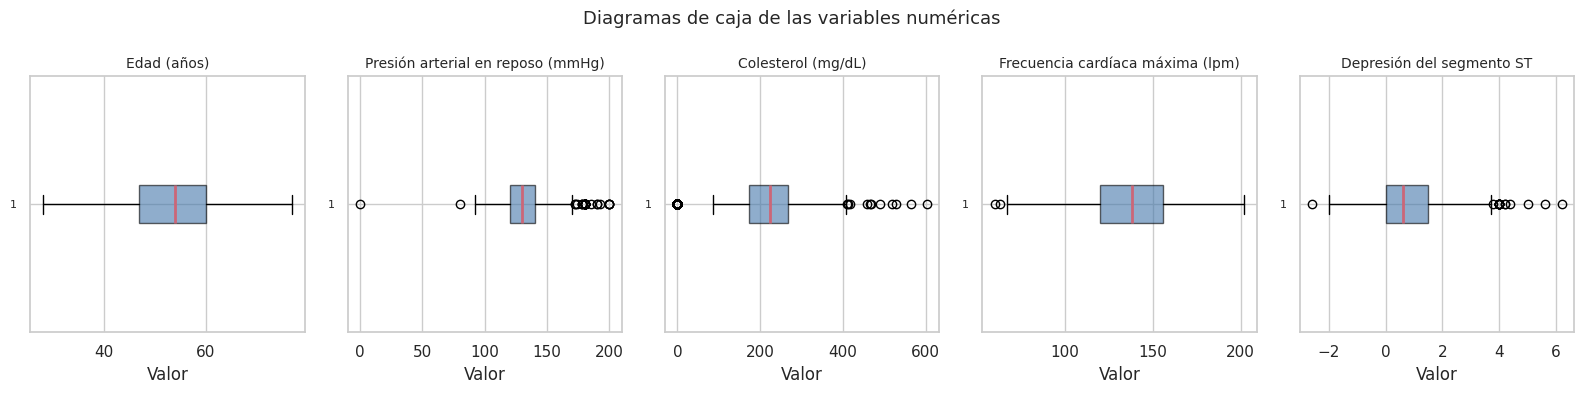

In [ ]:
# @title
# Detectar valores atípicos con el criterio de rango intercuartílico (IQR).
# Un valor se considera atípico si está por fuera de:
#   [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR]
# Este criterio es descriptivo: no decide si un valor es un error.
iqr_results = []

for column in numeric_columns:
    values = numeric_view[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = values[(values < lower_limit) | (values > upper_limit)]

    iqr_results.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "Límite inferior": lower_limit,
        "Límite superior": upper_limit,
        "Atípicos": len(outliers),
        "Atípicos (%)": round(len(outliers) / len(values) * 100, 2),
        "Mínimo observado": values.min(),
        "Máximo observado": values.max(),
    })

display(pd.DataFrame(iqr_results).round(2))

# Visualizar los valores atípicos con diagramas de caja.
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, column in zip(axes, numeric_columns):
    values = numeric_view[column].dropna()

    ax.boxplot(
        values,
        vert=False,
        patch_artist=True,
        boxprops=dict(facecolor="#4477AA", alpha=0.6),
        medianprops=dict(color="#CC6677", linewidth=2),
    )

    ax.set_title(numeric_labels[column], fontsize=10)
    ax.set_xlabel("Valor")
    ax.tick_params(axis="y", labelsize=8)

fig.suptitle("Diagramas de caja de las variables numéricas", fontsize=13)
plt.tight_layout()
plt.show()

**Respuesta**

- **¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?** No se detectaron ausencias explícitas: **0 valores nulos** en las 12 variables y **0 cadenas vacías** en las variables de texto. Sin embargo, sí se identificó un problema de baja calidad encubierto: **172 registros con `Cholesterol == 0` (18.7%) y 1 registro con `RestingBP == 0`**, valores fisiológicamente imposibles que en la práctica funcionan como información no disponible codificada como cero.

- **¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?** No. La lectura con codificación UTF-8 fue limpia, **0 valores numéricos fallaron la conversión** y todas las categorías de texto coinciden con las documentadas en la fuente. No hay documentos ilegibles.

- **¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?** No. El conjunto es **homogéneo**: un único archivo CSV tabular con 12 columnas consistentes, sin mezcla de formatos ni estructuras adicionales.

- **¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?** Sí, se identificaron mediante verificaciones formales:
  - **Duplicados:** 0 filas duplicadas.
  - **Datos faltantes:** 0 nulos explícitos, pero 172 ceros en `Cholesterol` y 1 cero en `RestingBP` que funcionan como datos faltantes encubiertos.
  - **Valores atípicos (criterio IQR):**
    - `Age`: 0 atípicos (rango 28–77 años, plausible).
    - `RestingBP`: 28 atípicos (3.05%), entre ellos el valor 0; los restantes son presiones altas (hasta 200 mmHg), clínicamente posibles.
    - `Cholesterol`: 183 atípicos (19.93%), pero **172 de ellos son precisamente los ceros** ya identificados; solo ~11 valores superan el límite superior (407.6 mg/dL), con un máximo de 603 mg/dL, extremo pero posible.
    - `MaxHR`: 2 atípicos (0.22%), frecuencias de 60 y 202 lpm, plausibles.
    - `Oldpeak`: 16 atípicos (1.74%), incluye valores negativos (mínimo −2.6) que en la literatura se asocian con mejor respuesta al ejercicio, no necesariamente errores.
  - En consecuencia, **no se eliminan ni imputan valores en esta fase**: los atípicos son en su mayoría valores clínicamente plausibles o los ceros ya documentados. Su tratamiento se decidirá en la fase de preparación.

### **1.3. Tipos de variables**
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

**Tipos de variables y análisis descriptivo**

Se presenta el diccionario de datos con el tipo de almacenamiento y el tipo conceptual de cada variable, se analiza la distribución de la variable objetivo y se realiza el análisis descriptivo de las variables predictoras.

In [ ]:
# @title
# Construir el diccionario de datos con el tipo conceptual
# de cada variable (definido en la fase 1).
conceptual_types = {
    **{column: "Numérica" for column in numeric_columns},
    **{column: "Categórica" for column in categorical_columns},
    target_column: "Objetivo binario",
}

# Descripciones tomadas de la documentación de la fuente.
variable_descriptions = {
    "Age": "Edad del paciente en años",
    "Sex": "Sexo del paciente (M/F)",
    "ChestPainType": "Tipo de dolor torácico (TA/ATA/NAP/ASY)",
    "RestingBP": "Presión arterial en reposo (mmHg)",
    "Cholesterol": "Colesterol sérico (mg/dL)",
    "FastingBS": "Glucemia en ayunas > 120 mg/dL (0/1)",
    "RestingECG": "Resultado del ECG en reposo (Normal/ST/LVH)",
    "MaxHR": "Frecuencia cardíaca máxima alcanzada",
    "ExerciseAngina": "Angina inducida por ejercicio (Y/N)",
    "Oldpeak": "Depresión del segmento ST (valor numérico)",
    "ST_Slope": "Pendiente del segmento ST (Up/Flat/Down)",
    "HeartDisease": "Enfermedad cardíaca diagnosticada (0/1)",
}

# Reunir en una tabla el tipo de almacenamiento y el significado.
data_dictionary = pd.DataFrame({
    "Variable": df.columns,
    "Descripción": [
        variable_descriptions.get(column, "Requiere revisión")
        for column in df.columns
    ],
    "Tipo de almacenamiento": [
        str(df[column].dtype) for column in df.columns
    ],
    "Tipo conceptual": [
        conceptual_types.get(column, "Requiere revisión")
        for column in df.columns
    ],
    "Valores distintos": [
        df[column].nunique(dropna=True) for column in df.columns
    ],
})

display(data_dictionary)

,Variable,Descripción,Tipo de almacenamiento,Tipo conceptual,Valores distintos
0,Age,Edad del paciente en años,int64,Numérica,50
1,Sex,Sexo del paciente (M/F),object,Categórica,2
2,ChestPainType,Tipo de dolor torácico (TA/ATA/NAP/ASY),object,Categórica,4
3,RestingBP,Presión arterial en reposo (mmHg),int64,Numérica,67
4,Cholesterol,Colesterol sérico (mg/dL),int64,Numérica,222
5,FastingBS,Glucemia en ayunas > 120 mg/dL (0/1),int64,Categórica,2
6,RestingECG,Resultado del ECG en reposo (Normal/ST/LVH),object,Categórica,3
7,MaxHR,Frecuencia cardíaca máxima alcanzada,int64,Numérica,119
8,ExerciseAngina,Angina inducida por ejercicio (Y/N),object,Categórica,2
9,Oldpeak,Depresión del segmento ST (valor numérico),float64,Numérica,53


,Clase,Descripción,Cantidad,Porcentaje
0,0,Sin enfermedad cardíaca,410,44.66
1,1,Con enfermedad cardíaca,508,55.34


Ratio de desbalance (mayoritaria/menoritaria): 1.24


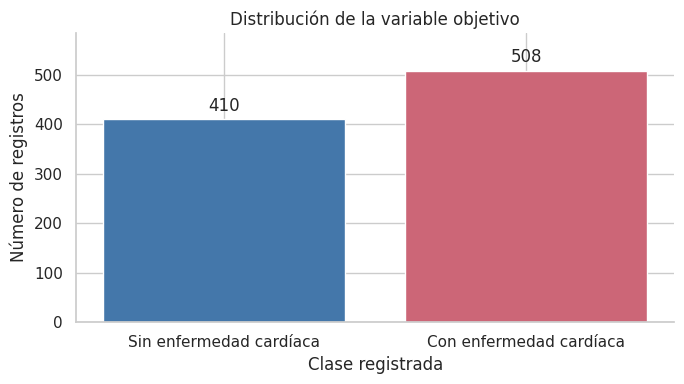

In [ ]:
# @title
# Verificar que la variable objetivo esté completa y use las clases esperadas.
if df[target_column].isna().any():
    raise ValueError(
        "La variable objetivo contiene valores ausentes. "
        "Revisa estos registros antes de continuar."
    )

if not df[target_column].isin([0, 1]).all():
    raise ValueError(
        "La variable objetivo contiene etiquetas diferentes de 0 y 1."
    )

# Mantener un orden explícito: primero clase 0 y después clase 1.
class_counts = (
    df[target_column]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_summary = pd.DataFrame({
    "Clase": [0, 1],
    "Descripción": [
        target_labels[0],
        target_labels[1],
    ],
    "Cantidad": class_counts.to_numpy(),
    "Porcentaje": (
        class_counts.to_numpy() / len(df) * 100
    ).round(2),
})

display(target_summary)

# Calcular el ratio de desbalance entre clases.
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Ratio de desbalance (mayoritaria/menoritaria): {imbalance_ratio:.2f}")

# Graficar la cantidad de registros por clase.
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    target_summary["Descripción"],
    target_summary["Cantidad"],
    color=["#4477AA", "#CC6677"],
    edgecolor="white",
)

ax.bar_label(bars, padding=3)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Clase registrada")
ax.set_ylabel("Número de registros")
ax.set_ylim(0, class_counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max,Mediana
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0,54.0
RestingBP,918.0,132.40,18.51,0.0,120.00,130.0,140.0,200.0,130.0
Cholesterol,918.0,198.80,109.38,0.0,173.25,223.0,267.0,603.0,223.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0,138.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2,0.6


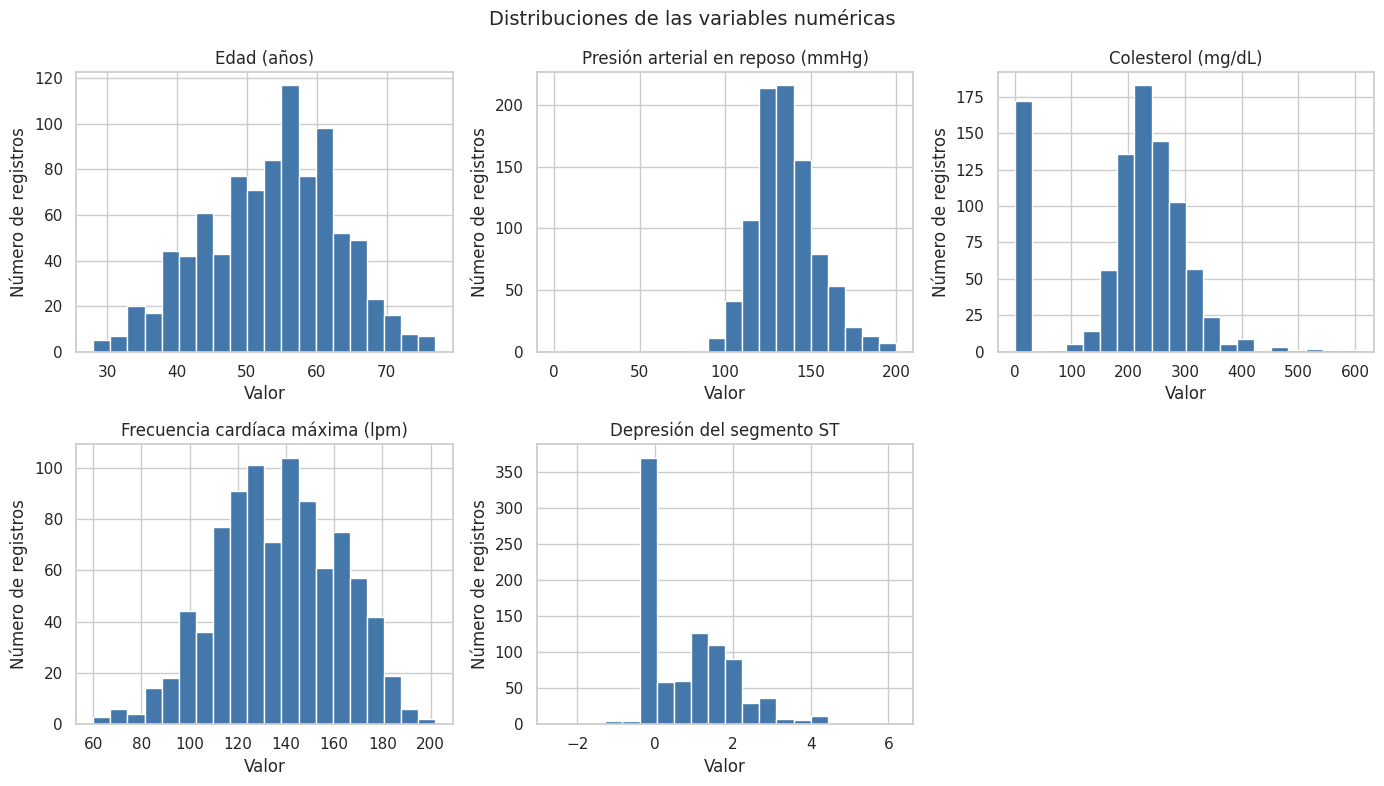

In [ ]:
# @title
# Resumen estadístico de las variables numéricas.
numeric_stats = numeric_view.describe().T

# Agregar la mediana para complementar la media,
# útil cuando hay valores extremos.
numeric_stats["Mediana"] = numeric_view.median()

display(numeric_stats.round(2))

# Crear una cuadrícula de histogramas para las variables numéricas.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    values = numeric_view[column].dropna()

    ax.hist(
        values,
        bins=20,
        color="#4477AA",
        edgecolor="white",
    )

    ax.set_title(numeric_labels[column])
    ax.set_xlabel("Valor")
    ax.set_ylabel("Número de registros")

# Ocultar el espacio sobrante de la cuadrícula.
for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

fig.suptitle("Distribuciones de las variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()


Distribución de Sexo (Sex):


,Valor,Cantidad,Porcentaje (%)
0,M,725,78.98
1,F,193,21.02



Distribución de Tipo de dolor torácico (ChestPainType):


,Valor,Cantidad,Porcentaje (%)
0,ASY,496,54.03
1,NAP,203,22.11
2,ATA,173,18.85
3,TA,46,5.01



Distribución de Glucemia en ayunas > 120 mg/dL (FastingBS):


...

,Valor,Cantidad,Porcentaje (%)
0,Normal,552,60.13
1,LVH,188,20.48
2,ST,178,19.39



Distribución de Angina inducida por ejercicio (ExerciseAngina):


,Valor,Cantidad,Porcentaje (%)
0,N,547,59.59
1,Y,371,40.41



Distribución de Pendiente del segmento ST (ST_Slope):


,Valor,Cantidad,Porcentaje (%)
0,Flat,460,50.11
1,Up,395,43.03
2,Down,63,6.86


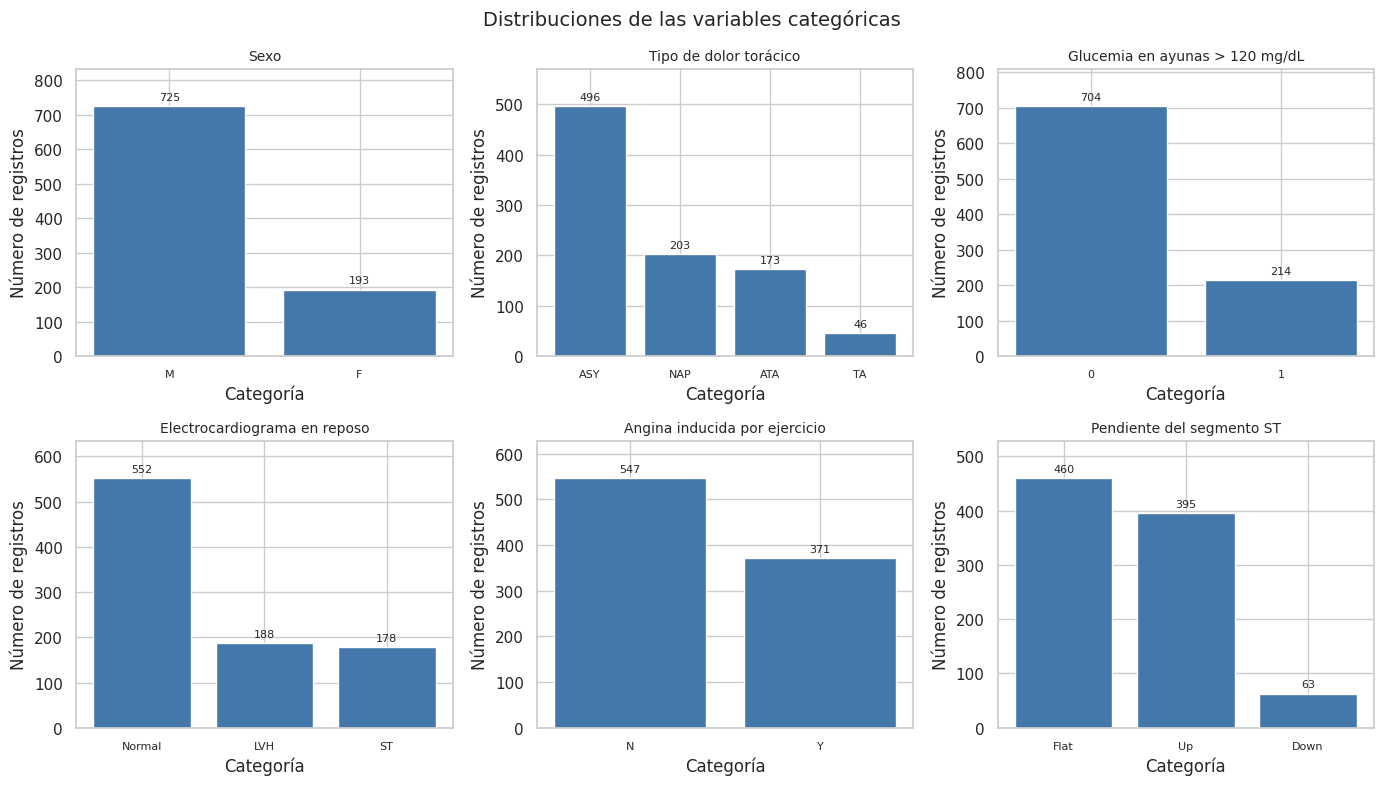

In [ ]:
# @title
# Tabla de frecuencias de cada variable categórica.
for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)
    percentages = (counts / len(df) * 100).round(2)

    frequency_table = pd.DataFrame({
        "Valor": counts.index,
        "Cantidad": counts.to_numpy(),
        "Porcentaje (%)": percentages.to_numpy(),
    })

    print(f"\nDistribución de {categorical_labels[column]} ({column}):")
    display(frequency_table)

# Cuadrícula de gráficos de barras para las variables categóricas.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    counts = df[column].value_counts(dropna=False)

    bars = ax.bar(
        counts.index.astype(str),
        counts.to_numpy(),
        color="#4477AA",
        edgecolor="white",
    )

    ax.bar_label(bars, padding=3, fontsize=8)
    ax.set_title(categorical_labels[column], fontsize=10)
    ax.set_xlabel("Categoría")
    ax.set_ylabel("Número de registros")
    ax.set_ylim(0, counts.max() * 1.15)
    ax.tick_params(axis="x", labelsize=8)

# Ocultar el espacio sobrante de la cuadrícula.
for ax in axes[len(categorical_columns):]:
    ax.set_visible(False)

fig.suptitle("Distribuciones de las variables categóricas", fontsize=14)
plt.tight_layout()
plt.show()

Adicionalmente y por curiosidad, quiero aislar todos los registros con colesterol 0, ya que parecen muy atípicos

In [ ]:
# @title
# Aislar los registros con colesterol igual a cero.
cholesterol_zero_df = df[df["Cholesterol"] == 0].copy()

print(f"Cantidad de registros con Cholesterol == 0: {len(cholesterol_zero_df)}")
display(cholesterol_zero_df.head(20))

# Resumen rápido de esta subpoblación.
cholesterol_zero_summary = pd.DataFrame({
    "Variable": ["Edad", "RestingBP", "MaxHR", "Oldpeak", "HeartDisease"],
    "Media": [
        cholesterol_zero_df["Age"].mean(),
        cholesterol_zero_df["RestingBP"].mean(),
        cholesterol_zero_df["MaxHR"].mean(),
        cholesterol_zero_df["Oldpeak"].mean(),
        cholesterol_zero_df["HeartDisease"].mean(),
    ],
    "Mediana": [
        cholesterol_zero_df["Age"].median(),
        cholesterol_zero_df["RestingBP"].median(),
        cholesterol_zero_df["MaxHR"].median(),
        cholesterol_zero_df["Oldpeak"].median(),
        cholesterol_zero_df["HeartDisease"].median(),
    ],
})

display(cholesterol_zero_summary.round(2))

# Distribución de la variable objetivo dentro de este subconjunto.
cholesterol_zero_target = (
    cholesterol_zero_df["HeartDisease"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

display(
    pd.DataFrame({
        "Clase": [0, 1],
        "Descripción": ["Sin enfermedad cardíaca", "Con enfermedad cardíaca"],
        "Cantidad": cholesterol_zero_target.to_numpy(),
        "Porcentaje": (cholesterol_zero_target / len(cholesterol_zero_df) * 100).round(2),
    })
)

Cantidad de registros con Cholesterol == 0: 172


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
293,65,M,ASY,115,0,0,Normal,93,Y,0.0,Flat,1
294,32,M,TA,95,0,1,Normal,127,N,0.7,Up,1
295,61,M,ASY,105,0,1,Normal,110,Y,1.5,Up,1
296,50,M,ASY,145,0,1,Normal,139,Y,0.7,Flat,1
297,57,M,ASY,110,0,1,ST,131,Y,1.4,Up,1
298,51,M,ASY,110,0,1,Normal,92,N,0.0,Flat,1
299,47,M,ASY,110,0,1,ST,149,N,2.1,Up,1
300,60,M,ASY,160,0,1,Normal,149,N,0.4,Flat,1
301,55,M,ATA,140,0,0,ST,150,N,0.2,Up,0
302,53,M,ASY,125,0,1,Normal,120,N,1.5,Up,1


,Variable,Media,Mediana
0,Edad,56.24,57.50
1,RestingBP,129.68,129.00
2,MaxHR,121.99,120.00
3,Oldpeak,0.83,0.75
4,HeartDisease,0.88,1.00


,Clase,Descripción,Cantidad,Porcentaje
HeartDisease,,,,
0,0,Sin enfermedad cardíaca,20,11.63
1,1,Con enfermedad cardíaca,152,88.37


Interesantemente no todos los que tienen colesterol 0 tienen enfermedades cardiacas, igualmente parece mu atípico, igualmente no le veo el sentido ya que la gráfica no tiene una distribución "natural", y una revisión rápida en google me dice que no es posible tener colesterol en 0, pero viendo los sources del dataset no veo uno que justifique el colesterol 0

**Respuesta**

- **¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?** Sí. La variable objetivo es **`HeartDisease`** y es **categórica binaria**: toma el valor 1 cuando el paciente tiene enfermedad cardíaca diagnosticada y 0 en caso contrario. Se trata, por tanto, de un problema de **clasificación binaria supervisada**.

- **Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.** La distribución es: **508 registros con enfermedad (55.34%)** frente a **410 registros sin enfermedad (44.66%)**, con un **ratio de desbalance de 1.24:1**. El desbalance es **leve** (está lejos de ratios problemáticos como 10:1), por lo que no exige técnicas de balanceo agresivas, pero sí justifica: (i) una **partición estratificada** por `HeartDisease` en la fase de modelado, y (ii) evaluar con métricas adicionales a la exactitud (precisión, recall, F1), dado que un clasificador trivial que predijera siempre la clase mayoritaria alcanzaría un 55.3% de exactitud.

- **¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán al modelo y hacer un análisis descriptivo de las mismas.** Sí: además de la objetivo, el conjunto tiene **11 variables predictoras** (5 numéricas y 6 categóricas). **Todas se incorporarán al modelo**, por tres razones: (i) son **factores de riesgo cardiovascular reconocidos clínicamente** (edad, presión arterial, colesterol, glucemia, resultados de ECG y de prueba de esfuerzo); (ii) están **completas** (sin nulos ni categorías fuera de la documentación, según la sección 1.2); y (iii) **no presentan redundancia** entre sí (sección 1.4), por lo que ninguna debe excluirse por este criterio. Su análisis descriptivo:

  **Variables numéricas** (resumen estadístico e histogramas de las celdas anteriores):
  - **`Age` (edad):** media de 53.5 años, rango 28–77, distribución aproximadamente simétrica con mediana de 54 años. Refleja una población adulta, coherente con un estudio de enfermedad cardíaca.
  - **`RestingBP` (presión arterial en reposo):** media de 132.4 mmHg y mediana de 130 mmHg, valores típicos de la población clínica; incluye el valor 0 ya identificado como dato faltante encubierto.
  - **`Cholesterol` (colesterol sérico):** media de 198.8 mg/dL y mediana de 223 mg/dL; la media está arrastrada hacia abajo por el **pico anómalo de 172 registros con valor 0**, claramente visible en el histograma como una barra aislada en el origen.
  - **`MaxHR` (frecuencia cardíaca máxima):** media de 136.8 lpm, rango 60–202, distribución aproximadamente simétrica.
  - **`Oldpeak` (depresión del segmento ST):** media de 0.89 y mediana de 0.6, con **asimetría positiva**: la mayoría de pacientes se concentra en valores bajos (incluido 0) y una cola derecha llega hasta 6.2.

  **Variables categóricas** (tablas de frecuencia y gráficos de barras de las celdas anteriores):
  - **`Sex`:** fuertemente sesgada — **725 hombres (78.98%)** frente a **193 mujeres (21.02%)**. Este desbalance debe tenerse en cuenta al interpretar el desempeño del modelo por sexo.
  - **`ChestPainType`:** dominada por el dolor asintomático **`ASY` (496 registros, 54.0%)**, seguido de `NAP` (22.1%), `ATA` (18.8%) y `TA` (5.0%). La alta proporción de pacientes asintomáticos es característica de este tipo de cohortes clínicas.
  - **`FastingBS`:** 76.7% de pacientes con glucemia en ayunas ≤ 120 mg/dL y 23.3% por encima de ese umbral.
  - **`RestingECG`:** mayoritariamente `Normal` (60.1%), seguido de `LVH` (20.5%) y `ST` (19.4%).
  - **`ExerciseAngina`:** 59.6% sin angina inducida por ejercicio (`N`) y 40.4% con ella (`Y`).
  - **`ST_Slope`:** `Flat` es la categoría más frecuente (50.1%), seguida de `Up` (43.0%) y `Down` (6.9%).

  En conjunto, las distribuciones son clínicamente plausibles; los únicos comportamientos anómalos son el pico de `Cholesterol == 0` y el sesgo de `Sex`, ambos ya documentados y con tratamiento diferido a la fase de preparación.

### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

**Análisis de relaciones entre variables**

Se analizan las relaciones mediante tres enfoques complementarios:

1. **Correlación entre variables numéricas** (Pearson y Spearman), incluyendo la variable objetivo, para detectar asociaciones lineales y monótonas.
2. **Comparación de distribuciones por clase** (diagramas de caja de cada numérica según `HeartDisease`), para detectar variables que se comportan diferente en pacientes con y sin enfermedad.
3. **Tablas cruzadas de categóricas vs. objetivo** (proporciones por fila), para detectar categorías asociadas a la clase positiva.

Al final se examina la **redundancia** entre variables predictoras.

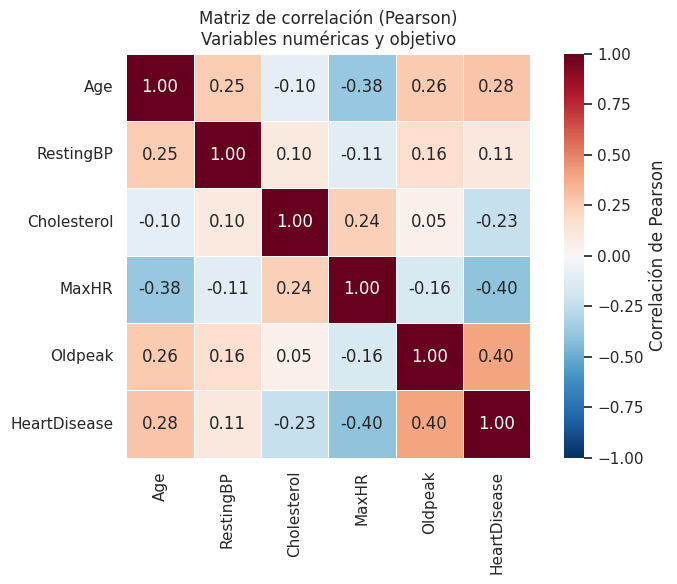

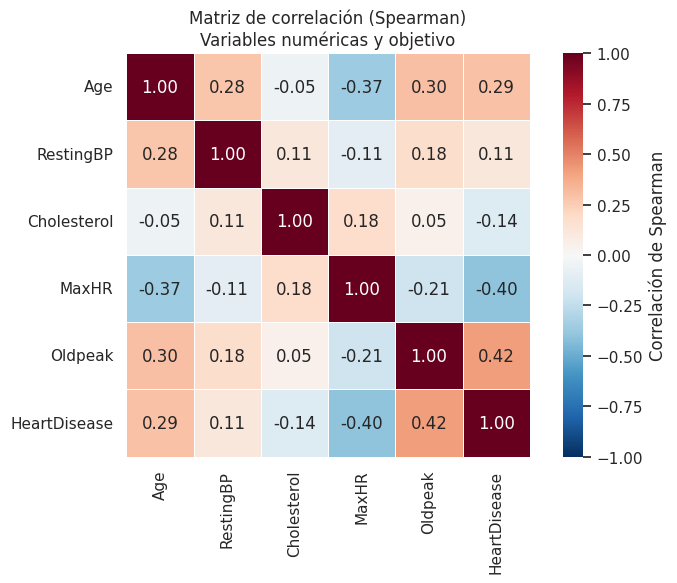

In [ ]:
# @title
# Matriz de correlación de Pearson: numéricas + variable objetivo.
# La variable objetivo (0/1) se incluye para medir su asociación
# lineal con cada numérica (correlación punto-biserial).
correlation_columns = numeric_columns + [target_column]

pearson_matrix = df[correlation_columns].corr(method="pearson")

# Visualizar la matriz como mapa de calor.
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    pearson_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlación de Pearson"},
    ax=ax,
)

ax.set_title("Matriz de correlación (Pearson)\nVariables numéricas y objetivo")
plt.tight_layout()
plt.show()

# Complemento con Spearman: sensible a relaciones monótonas
# y menos afectada por valores extremos (útil para Oldpeak).
spearman_matrix = df[correlation_columns].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    spearman_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlación de Spearman"},
    ax=ax,
)

ax.set_title(
    "Matriz de correlación (Spearman)\nVariables numéricas y objetivo"
)
plt.tight_layout()
plt.show()

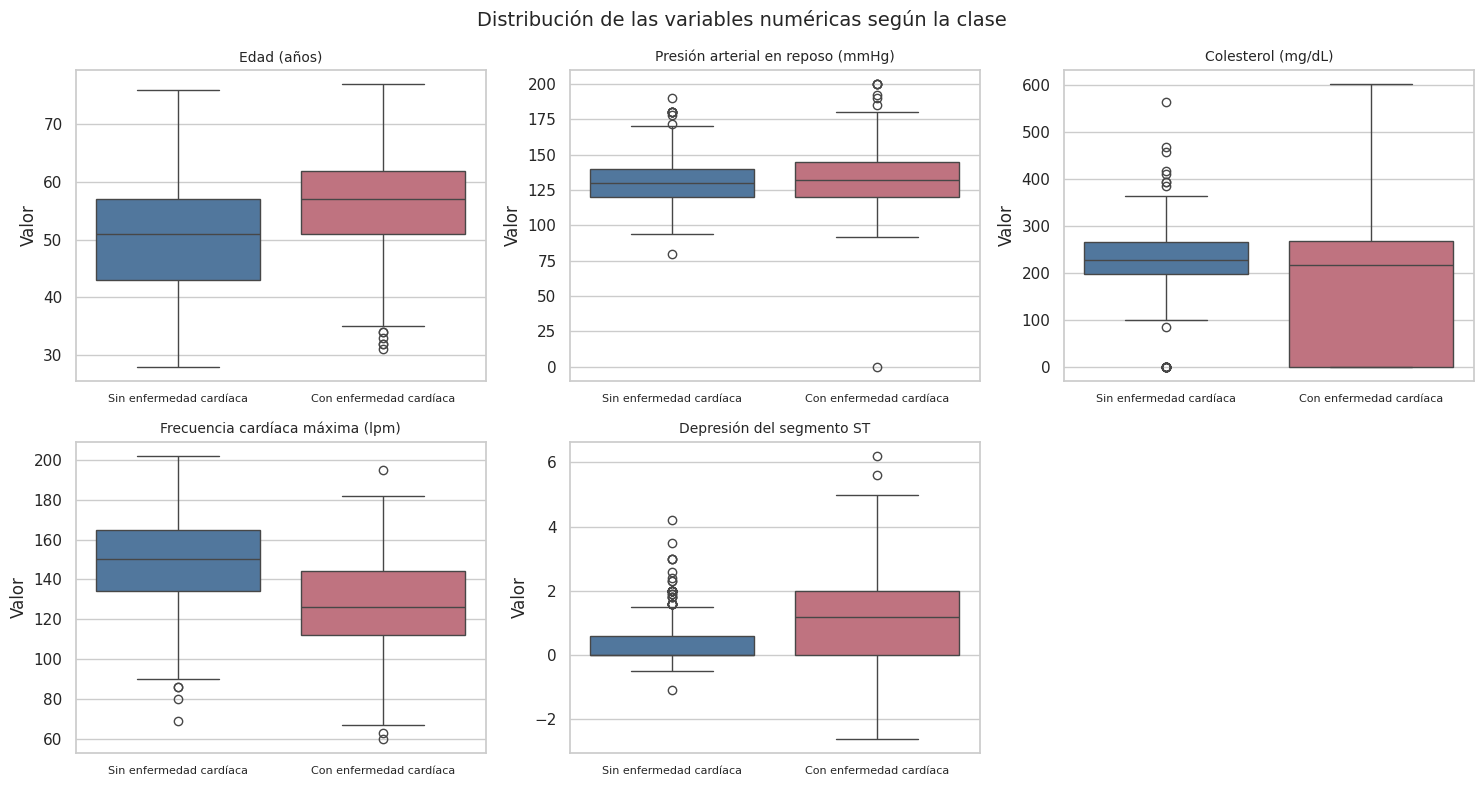

,Mediana sin enfermedad,Mediana con enfermedad
Age,51.0,57.0
RestingBP,130.0,132.0
Cholesterol,227.0,217.0
MaxHR,150.0,126.0
Oldpeak,0.0,1.2


In [ ]:
# @title
# Comparar la distribución de cada variable numérica por clase.
# Se crea una copia auxiliar con etiquetas legibles de la clase
# únicamente para las gráficas; los datos no se modifican.
plot_df = df.copy(deep=True)
plot_df["Clase"] = plot_df[target_column].map(target_labels)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(
        data=plot_df,
        x="Clase",
        y=column,
        hue="Clase",
        order=[target_labels[0], target_labels[1]],
        palette=["#4477AA", "#CC6677"],
        legend=False,
        ax=ax,
    )

    ax.set_title(numeric_labels[column], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Valor")
    ax.tick_params(axis="x", labelsize=8)

# Ocultar el espacio sobrante de la cuadrícula.
for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

fig.suptitle(
    "Distribución de las variables numéricas según la clase",
    fontsize=14,
)
plt.tight_layout()
plt.show()

# Tabla de medianas por clase para cuantificar las diferencias visuales.
# Se impone un orden explícito de las clases: groupby ordena
# alfabéticamente y "Con enfermedad" precedería a "Sin enfermedad".
medians_by_class = (
    plot_df.groupby("Clase")[numeric_columns]
    .median()
    .reindex([target_labels[0], target_labels[1]])
    .T
)

medians_by_class.columns = [
    "Mediana sin enfermedad",
    "Mediana con enfermedad",
]

display(medians_by_class)


Proporción de enfermedad cardíaca por Sexo (Sex):


,% Sin enfermedad,% Con enfermedad
Sex,,
F,74.09,25.91
M,36.83,63.17


Registros por categoría: {'M': np.int64(725), 'F': np.int64(193)}

Proporción de enfermedad cardíaca por Tipo de dolor torácico (ChestPainType):


,% Sin enfermedad,% Con enfermedad
ChestPainType,,
ASY,20.97,79.03
ATA,86.13,13.87
NAP,64.53,35.47
TA,56.52,43.48


Registros por categoría: {'ASY': np.int64(496), 'NAP': np.int64(203), 'ATA': np.int64(173), 'TA': np.int64(46)}

Proporción de enfermedad cardíaca por Glucemia en ayunas > 120 mg/dL (FastingBS):


...

Registros por categoría: {'Normal': np.int64(552), 'LVH': np.int64(188), 'ST': np.int64(178)}

Proporción de enfermedad cardíaca por Angina inducida por ejercicio (ExerciseAngina):


,% Sin enfermedad,% Con enfermedad
ExerciseAngina,,
N,64.90,35.10
Y,14.82,85.18


Registros por categoría: {'N': np.int64(547), 'Y': np.int64(371)}

Proporción de enfermedad cardíaca por Pendiente del segmento ST (ST_Slope):


,% Sin enfermedad,% Con enfermedad
ST_Slope,,
Down,22.22,77.78
Flat,17.17,82.83
Up,80.25,19.75


Registros por categoría: {'Flat': np.int64(460), 'Up': np.int64(395), 'Down': np.int64(63)}


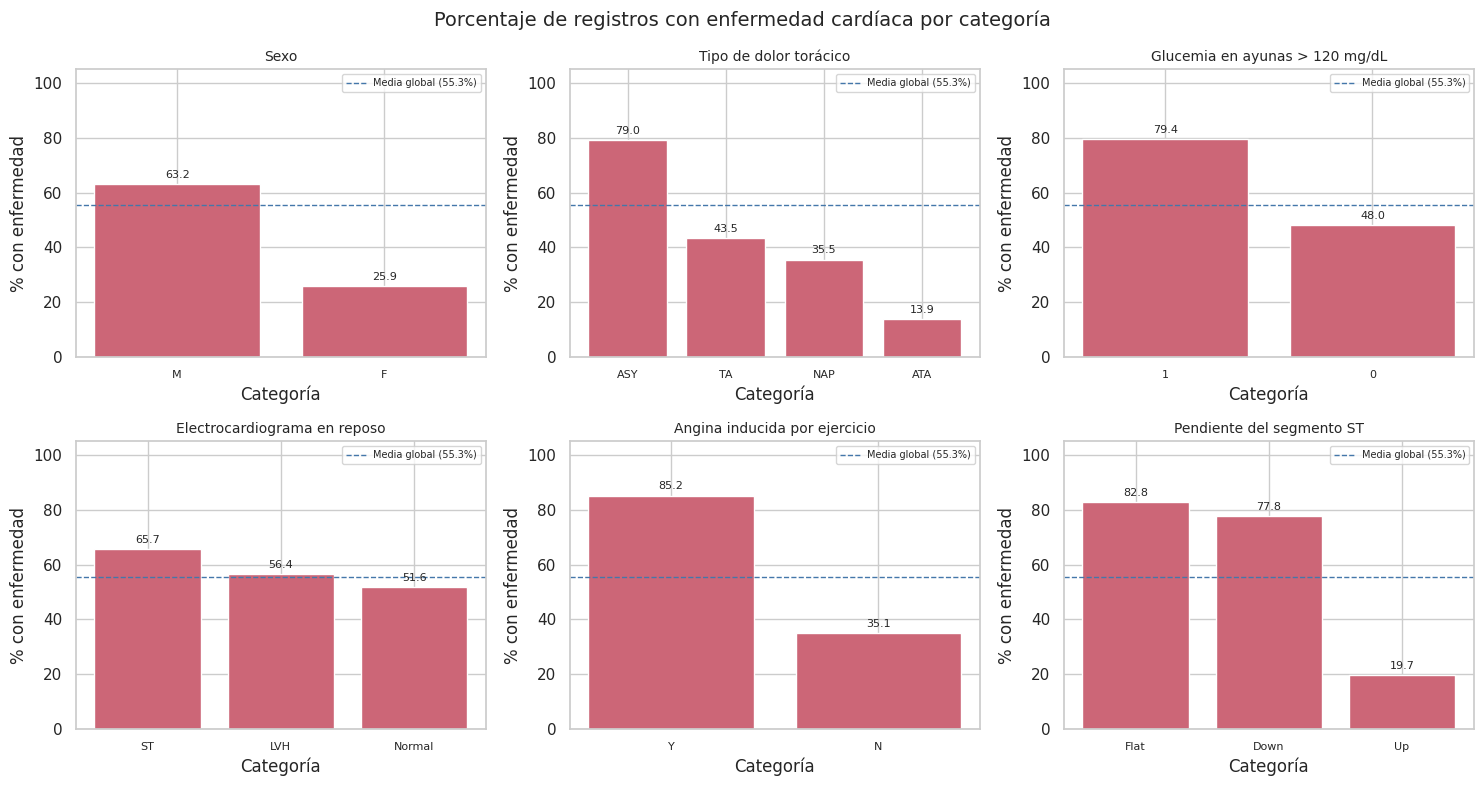

In [ ]:
# @title
# Tablas cruzadas de cada categórica contra la variable objetivo.
# normalize="index" calcula la proporción de cada clase dentro de
# cada categoría: responde "de los pacientes con la categoría X,
# ¿qué proporción tiene enfermedad cardíaca?".
for column in categorical_columns:
    crosstab = pd.crosstab(
        df[column],
        df[target_column],
        normalize="index",
    ) * 100

    crosstab.columns = [
        "% Sin enfermedad",
        "% Con enfermedad",
    ]

    counts = df[column].value_counts()

    print(
        f"\nProporción de enfermedad cardíaca por "
        f"{categorical_labels[column]} ({column}):"
    )
    display(crosstab.round(2))
    print(
        "Registros por categoría:",
        dict(counts),
    )

# Visualización compacta: proporción de clase positiva por categoría.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    crosstab = pd.crosstab(df[column], df[target_column], normalize="index")

    positive_proportion = (crosstab[1] * 100).sort_values(ascending=False)

    bars = ax.bar(
        positive_proportion.index.astype(str),
        positive_proportion.to_numpy(),
        color="#CC6677",
        edgecolor="white",
    )

    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
    ax.axhline(
        df[target_column].mean() * 100,
        color="#4477AA",
        linestyle="--",
        linewidth=1,
        label=f"Media global ({df[target_column].mean()*100:.1f}%)",
    )
    ax.set_title(categorical_labels[column], fontsize=10)
    ax.set_xlabel("Categoría")
    ax.set_ylabel("% con enfermedad")
    ax.set_ylim(0, 105)
    ax.tick_params(axis="x", labelsize=8)
    ax.legend(fontsize=7)

# Ocultar el espacio sobrante de la cuadrícula.
for ax in axes[len(categorical_columns):]:
    ax.set_visible(False)

fig.suptitle(
    "Porcentaje de registros con enfermedad cardíaca por categoría",
    fontsize=14,
)
plt.tight_layout()
plt.show()

In [ ]:
# @title
# Análisis de redundancia entre variables predictoras numéricas.
# Se listan los pares con |correlación| > 0.7, umbral habitual
# para considerar redundancia relevante.
redundancy_threshold = 0.7

redundant_pairs = []

for i, col_a in enumerate(numeric_columns):
    for col_b in numeric_columns[i + 1:]:
        correlation = pearson_matrix.loc[col_a, col_b]

        if abs(correlation) > redundancy_threshold:
            redundant_pairs.append({
                "Variable A": col_a,
                "Variable B": col_b,
                "Correlación": round(correlation, 3),
            })

print(
    f"Pares de variables predictoras con |correlación| > "
    f"{redundancy_threshold}:"
)

if redundant_pairs:
    display(pd.DataFrame(redundant_pairs))
else:
    print(
        "No se encontraron pares redundantes entre las variables "
        "numéricas predictoras."
    )

# Correlación de cada variable numérica con la variable objetivo,
# ordenada por valor absoluto.
target_correlations = (
    pearson_matrix.loc[target_column, numeric_columns]
    .reindex(
        pearson_matrix.loc[target_column, numeric_columns]
        .abs()
        .sort_values(ascending=False)
        .index
    )
)

display(
    target_correlations
    .rename("Correlación con HeartDisease")
    .to_frame()
    .round(3)
)

Pares de variables predictoras con |correlación| > 0.7:
No se encontraron pares redundantes entre las variables numéricas predictoras.


,Correlación con HeartDisease
Oldpeak,0.404
MaxHR,-0.400
Age,0.282
Cholesterol,-0.233
RestingBP,0.108


**Respuesta**

- **Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.**

  **Entre variables numéricas predictoras:** la correlación más alta es **`Age`–`MaxHR` (−0.38)**: a mayor edad, menor frecuencia cardíaca máxima, lo cual es fisiológicamente esperado. Le siguen `Age`–`Oldpeak` (0.26) y `Age`–`RestingBP` (0.25), también coherentes clínicamente. Ninguna relación es lo bastante fuerte para considerar dependencia entre predictoras.

  **De las numéricas con la variable objetivo** (correlación punto-biserial, ordenada por magnitud):
  - **`Oldpeak` (0.40):** los pacientes con enfermedad presentan mayor depresión del segmento ST (mediana 1.2 vs 0.0).
  - **`MaxHR` (−0.40):** los pacientes con enfermedad alcanzan frecuencias cardíacas máximas menores (mediana 126 vs 150 lpm).
  - **`Age` (0.28):** los pacientes con enfermedad son mayores (mediana 57 vs 51 años).
  - **`Cholesterol` (−0.23):** correlación **negativa y contraintuitiva** (menor colesterol, más enfermedad). Este resultado está **distorsionado por los 172 registros con `Cholesterol == 0`**, que en su mayoría corresponden a pacientes con enfermedad; debe interpretarse con cautela y justifica el tratamiento de esos ceros en la fase de preparación.
  - **`RestingBP` (0.11):** relación débil (mediana 132 vs 130 mmHg).

  **De las categóricas con la variable objetivo** (proporción de enfermedad por categoría frente a la media global de 55.3%):
  - **`ExerciseAngina`:** la relación más marcada — 85.2% de enfermedad entre quienes presentan angina por ejercicio vs 35.1% entre quienes no.
  - **`ST_Slope`:** `Flat` (82.8%) y `Down` (77.8%) se asocian fuertemente con la enfermedad; `Up` es protectora (19.8%).
  - **`ChestPainType`:** el dolor asintomático `ASY` concentra 79.0% de enfermedad, mientras `ATA` solo 13.9%.
  - **`FastingBS`:** glucemia elevada se asocia con 79.4% de enfermedad vs 48.0%.
  - **`Sex`:** 63.2% de enfermedad en hombres vs 25.9% en mujeres (a interpretar con cautela dado el desbalance 725/193 y posibles factores de confusión).
  - **`RestingECG`:** diferencias moderadas (`ST` 65.7%, `LVH` 56.4%, `Normal` 51.6%).

  > Estas asociaciones son **descriptivas**: no establecen causalidad. Las correlaciones de Pearson y Spearman son consistentes entre sí, lo que indica que las relaciones detectadas son predominantemente monótonas.

- **Identifique si hay redundancia entre las variables para una posterior eliminación o selección.** **No se identificó redundancia relevante**: ningún par de variables predictoras numéricas supera el umbral de |correlación| > 0.7 (el máximo es 0.38 entre `Age` y `MaxHR`). Por lo tanto, **no se justifica la eliminación de variables por redundancia** y las 11 variables predictoras se conservarán para la fase de modelado, donde se evaluará su importancia mediante técnicas de selección si es necesario.

> **Advertencia metodológica:** la correlación lineal entre numéricas no captura relaciones con las categóricas (ni entre categóricas). El análisis de tablas cruzadas complementa esta limitación, pero la interacción conjunta de las variables solo será observable al entrenar los modelos en la siguiente fase.

In [ ]:
# Verificación final: la exploración no alteró el contenido de los datos.
# Si falla, revisar las celdas donde se pudo modificar df.
pd.testing.assert_frame_equal(df, df_original)
print("Verificación completada: los datos se conservan sin transformaciones.")

Verificación completada: los datos se conservan sin transformaciones.


## **2. Conclusiones de la Segunda Fase**
---

**Resumen general y calidad**

El conjunto *Heart Failure Prediction* contiene 918 registros y 12 variables almacenadas en un único formato CSV homogéneo de tamaño reducido (≈ 0.034 MB). No se detectaron valores nulos, cadenas vacías, duplicados, categorías fuera de la documentación ni problemas de codificación.

El principal hallazgo de calidad es la presencia de **valores cero fisiológicamente imposibles**: 172 registros con `Cholesterol == 0` (18.7% del conjunto) y 1 registro con `RestingBP == 0`. Estos valores no representan mediciones reales, sino **información no disponible codificada como cero**, y constituyen el principal insumo para las decisiones de preparación de la siguiente fase.

**Tipos de variables y desbalance**

La variable objetivo `HeartDisease` es categórica binaria, con un **desbalance leve** (55.34% con enfermedad vs 44.66% sin enfermedad, ratio 1.24:1). Este desbalance no es severo, pero justifica una partición estratificada y una evaluación con métricas adicionales a la exactitud.

Las 11 variables predictoras (5 numéricas y 6 categóricas) se incorporarán al modelo. Se documentaron sus distribuciones, incluyendo el fuerte sesgo de `Sex` (79% hombres) y la asimetría positiva de `Oldpeak`.

**Relaciones entre variables**

Las variables más asociadas con la enfermedad cardíaca son `Oldpeak` (r = 0.40), `MaxHR` (r = −0.40), `ExerciseAngina` (85.2% de enfermedad en la categoría `Y`), `ST_Slope` (82.8% en `Flat`) y `ChestPainType` (79.0% en `ASY`). Las relaciones son clínicamente coherentes y consistentes entre Pearson y Spearman.

**No se identificó redundancia** entre variables predictoras (máxima |correlación| = 0.38), por lo que no se justifica eliminar variables por este criterio.

Se identificó una **correlación contraintuitiva** entre `Cholesterol` y el objetivo (r = −0.23), atribuible a los ceros de colesterol concentrados en pacientes con enfermedad. Este hallazgo refuerza la necesidad de tratarlos en la fase de preparación.

**Estado del proyecto**

Esta fase dejó documentado el perfil completo de los datos: estructura, calidad, tipos de variables, distribuciones y relaciones. **No se aplicó ninguna transformación**: los datos se conservan idénticos a los originales.

Las decisiones que se derivan para la siguiente fase (preparación y modelado) son:

1. Tratar los ceros de `Cholesterol` y `RestingBP` como información no disponible (imputación o exclusión justificada).
2. Realizar una partición estratificada por `HeartDisease`.
3. Codificar las categóricas y escalar las numéricas cuando el modelo lo requiera, aprendiendo los parámetros solo del conjunto de entrenamiento.
4. Conservar las 11 variables predictoras, al no existir redundancia.
5. Evaluar con precisión, recall, F1 y matriz de confusión, atendiendo a los falsos negativos.

Todavía no se ha entrenado ni evaluado ningún modelo predictivo.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*